# Task 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def L(w):
    return (w ** 2 - 1) ** 2


def g(w):
    return 4 * w ** 3 - 4 * w


print("L(w) = (w^2 - 1)^2,  g(w) = 4w^3 - 4w")
print("g(-1), g(0), g(1) =", g(-1.0), g(0.0), g(1.0), " -> the gradient is zero at both valleys and on the bump")

L(w) = (w^2 - 1)^2,  g(w) = 4w^3 - 4w
g(-1), g(0), g(1) = 0.0 0.0 0.0  -> the gradient is zero at both valleys and on the bump


### Hand calculations

**Item 1** ($\eta = 0.1$, $w_0 = 0.5$)

step 1: $g = 4 \cdot 0.125 - 4 \cdot 0.5 = -1.5$, new $w = 0.5 - 0.1 \cdot (-1.5) = 0.65$, new $L = (0.65^2 - 1)^2 = 0.3335$

step 2: $g = 4 \cdot 0.274625 - 4 \cdot 0.65 = -1.5015$, new $w = 0.65 + 0.15015 = 0.80015$, new $L = 0.1294$

**Prediction for $w_0 = -0.5$:** $L$ is symmetric, so it should be the mirror of the first run: $w_1 = -0.65$ and it ends in the valley at $-1$.

Check: $g(-0.5) = 4 \cdot (-0.125) + 2 = 1.5$, new $w = -0.5 - 0.15 = -0.65$. Correct.

**Item 2** ($w_0 = 1.5$, $g = 7.5$)

$\eta = 0.1$: $1.5 - 0.75 = 0.75$ -> right valley

$\eta = 0.2$: $1.5 - 1.5 = 0$ -> on the bump

$\eta = 0.24$: $1.5 - 1.8 = -0.3$ -> past the bump

In [2]:
print("item 1 (eta = 0.1, w0 = 0.5):")
w = 0.5
for step in (1, 2):
    gw = g(w)
    w_new = w - 0.1 * gw
    print(f"  step {step}: w = {w:.5f}  g = {gw:.5f}  new w = {w_new:.5f}  new L = {L(w_new):.5f}")
    w = w_new
assert np.isclose(g(0.5), -1.5)
assert np.isclose(0.5 - 0.1 * g(0.5), 0.65)

print("\nprediction check (eta = 0.1, w0 = -0.5):")
w_new = -0.5 - 0.1 * g(-0.5)
print(f"  g = {g(-0.5):.2f}  new w = {w_new:.2f}  new L = {L(w_new):.5f}")
assert np.isclose(w_new, -0.65)

print("\nitem 2 (w0 = 1.5, g = 7.5):")
assert np.isclose(g(1.5), 7.5)
for lr in (0.1, 0.2, 0.24):
    w_new = 1.5 - lr * g(1.5)
    print(f"  eta = {lr:<4}  new w = {w_new:6.3f}  new L = {L(w_new):.4f}")

item 1 (eta = 0.1, w0 = 0.5):
  step 1: w = 0.50000  g = -1.50000  new w = 0.65000  new L = 0.33351
  step 2: w = 0.65000  g = -1.50150  new w = 0.80015  new L = 0.12943

prediction check (eta = 0.1, w0 = -0.5):
  g = 1.50  new w = -0.65  new L = 0.33351

item 2 (w0 = 1.5, g = 7.5):
  eta = 0.1   new w =  0.750  new L = 0.1914
  eta = 0.2   new w =  0.000  new L = 1.0000
  eta = 0.24  new w = -0.300  new L = 0.8281


### Running GD in NumPy

run   eta    w0        w30     L(w30)
  1  0.10   0.5    1.00000   0.000000
  2  0.10  -0.5   -1.00000   0.000000
  3  0.10   1.5    1.00000   0.000000
  4  0.20   1.5    0.00000   1.000000
  5  0.24   1.5   -1.00534   0.000114


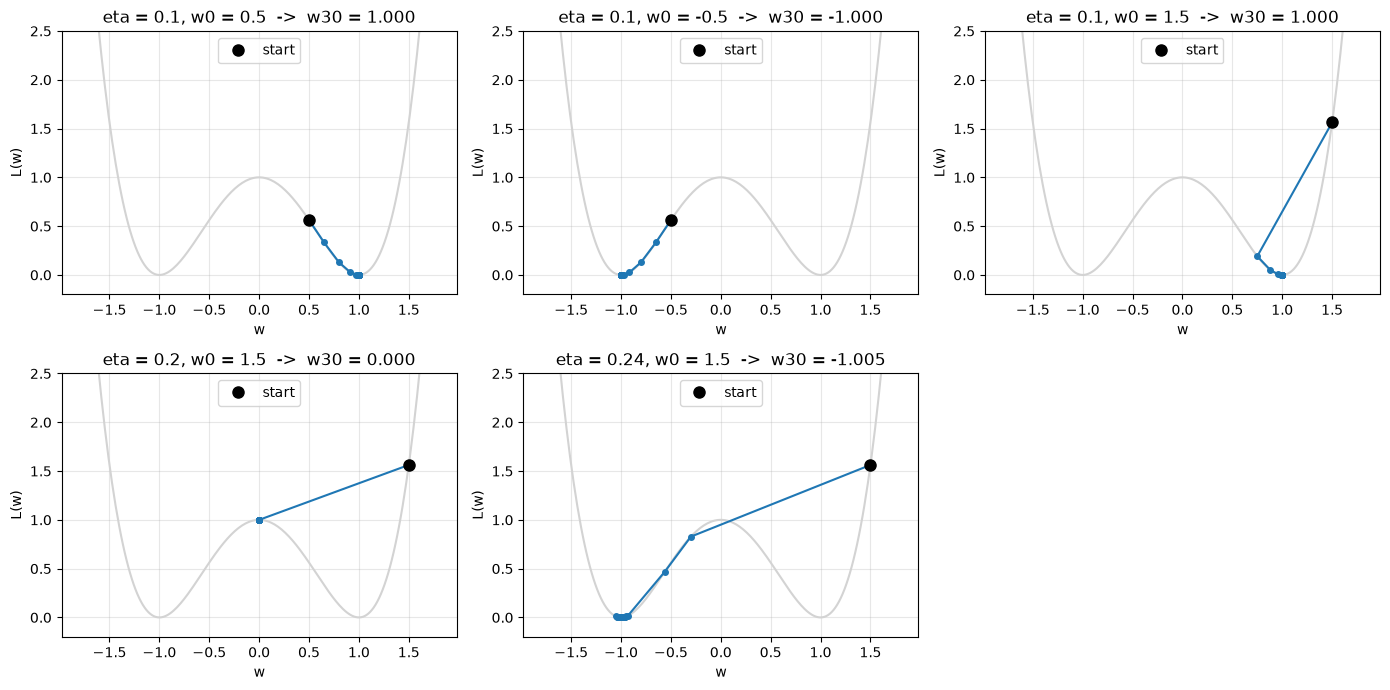

In [3]:
def gd_1d(lr, w0, n_updates=30):
    points = [w0]
    for _ in range(n_updates):
        points.append(points[-1] - lr * g(points[-1]))
    return points


runs = [(0.1, 0.5), (0.1, -0.5), (0.1, 1.5), (0.2, 1.5), (0.24, 1.5)]
results = [gd_1d(lr, w0) for lr, w0 in runs]
assert all(len(p) == 31 for p in results)

print(f"{'run':>3} {'eta':>5} {'w0':>5} {'w30':>10} {'L(w30)':>10}")
for i, ((lr, w0), pts) in enumerate(zip(runs, results), start=1):
    print(f"{i:3d} {lr:5.2f} {w0:5.1f} {pts[-1]:10.5f} {L(pts[-1]):10.6f}")

w_grid = np.linspace(-1.8, 1.8, 200)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, (lr, w0), points in zip(axes, runs, results):
    ax.plot(w_grid, (w_grid ** 2 - 1) ** 2, color="lightgray")
    ax.plot(points, (np.array(points) ** 2 - 1) ** 2, "o-", markersize=4)
    ax.plot(points[0], L(points[0]), "o", color="black", markersize=8, label="start")
    ax.set_ylim(-0.2, 2.5)
    ax.set_xlabel("w")
    ax.set_ylabel("L(w)")
    ax.set_title(f"eta = {lr}, w0 = {w0}  ->  w30 = {points[-1]:.3f}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper center")
axes[5].axis("off")
plt.tight_layout()
plt.show()

1. Which valley does each run end in? What decides it?
2. The run with $\eta = 0.2$ stops at $w = 0$. Is that a minimum? What does this tell you about points where the gradient is zero?
3. Where on the curve is the gradient largest, and where is it zero?

1) Runs 1 and 3 end in the right valley (+1), run 2 in the left one (-1). Run 5 also ends in the left valley (-1.005, still wobbling around -1). Run 4 is stuck at 0. What decides it is which side of the bump w is on after a step. Run 5 starts on the right but the step is so big that it jumps over the bump.

2) No, w = 0 is the top of the bump, so it's a maximum. Zero gradient only means the slope is flat there, it can be a min, a max or a saddle. GD got stuck only because 1.5 - 0.2 * 7.5 is exactly 0.

3) The gradient is zero at w = -1, 0, 1 (flat bottoms and flat top in the plots). It's largest on the steep outer sides far from the valleys (g = 7.5 already at w = 1.5). On the bump the steepest places are around w = ±0.58.

# Task 2

In [4]:
def L2(w):
    return w[0] ** 2 + 10 * w[1] ** 2


def grad2(w):
    return np.array([2 * w[0], 20 * w[1]])


start = np.array([2., 1.])
print("L(2, 1) =", L2(start), " gradient at (2, 1) =", grad2(start))

L(2, 1) = 14.0  gradient at (2, 1) = [ 4. 20.]


### Hand calculations

Start (2, 1): $g = (2 \cdot 2, 20 \cdot 1) = (4, 20)$, $L = 4 + 10 = 14$

**$\eta = 0.05$**

update 1: $(2 - 0.05 \cdot 4,\ 1 - 0.05 \cdot 20) = (1.8, 0)$, $L = 3.24$

update 2: $g = (3.6, 0)$, $(1.8 - 0.18,\ 0) = (1.62, 0)$, $L = 2.6244$

**$\eta = 0.09$**

update 1: $(2 - 0.09 \cdot 4,\ 1 - 0.09 \cdot 20) = (1.64, -0.8)$, $L = 2.6896 + 6.4 = 9.0896$

In [5]:
p = start.copy()
print("eta = 0.05:")
for step in (1, 2):
    p = p - 0.05 * grad2(p)
    print(f"  after update {step}: point = {p}  L = {L2(p):.4f}")
assert np.allclose(p, [1.62, 0.0]) and np.isclose(L2(p), 2.6244)
assert np.allclose(start - 0.05 * grad2(start), [1.8, 0.0])

p9 = start - 0.09 * grad2(start)
print("eta = 0.09:\n  after update 1: point =", p9, " L =", round(L2(p9), 4))
assert np.allclose(p9, [1.64, -0.8]) and np.isclose(L2(p9), 9.0896)

eta = 0.05:
  after update 1: point = [1.8 0. ]  L = 3.2400
  after update 2: point = [1.62 0.  ]  L = 2.6244
eta = 0.09:
  after update 1: point = [ 1.64 -0.8 ]  L = 9.0896


### Contour plot: the two arrows at (2, 1)

-g direction            : [-0.196 -0.981]
direction to minimum    : [-0.894 -0.447]
angle between them      : 52.1 degrees


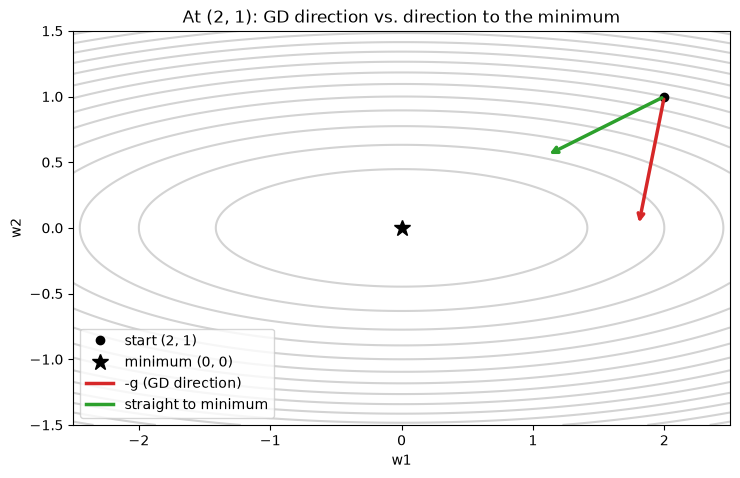

In [6]:
w1g, w2g = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.5, 1.5, 200))
Z = w1g ** 2 + 10 * w2g ** 2

neg_g = -grad2(start)
to_min = -start
u = neg_g / np.linalg.norm(neg_g)
v = to_min / np.linalg.norm(to_min)
angle = np.degrees(np.arccos(u @ v))
print("-g direction            :", np.round(u, 3))
print("direction to minimum    :", np.round(v, 3))
print(f"angle between them      : {angle:.1f} degrees")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.contour(w1g, w2g, w1g ** 2 + 10 * w2g ** 2, levels=15, colors="lightgray")
ax.plot(*start, "ko", label="start (2, 1)")
ax.plot(0, 0, "k*", markersize=12, label="minimum (0, 0)")
ax.annotate("", xy=start + 1.0 * u, xytext=start, arrowprops=dict(arrowstyle="->", color="tab:red", lw=2.5))
ax.annotate("", xy=start + 1.0 * v, xytext=start, arrowprops=dict(arrowstyle="->", color="tab:green", lw=2.5))
ax.plot([], [], color="tab:red", lw=2.5, label="-g (GD direction)")
ax.plot([], [], color="tab:green", lw=2.5, label="straight to minimum")
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.set_xlabel("w1"); ax.set_ylabel("w2")
ax.set_title("At (2, 1): GD direction vs. direction to the minimum")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

No. -g = (-4, -20) points almost straight down, but the direction to the minimum is (-2, -1), more to the left. About 52 degrees apart.

### Running GD (30 updates for four learning rates)

  eta  w1 factor  w2 factor        w1 (30)        w2 (30)         L (30)
 0.01       0.98       0.80          1.091      0.0012379         1.1902
 0.05       0.90       0.00       0.084782              0       0.007188
 0.09       0.82      -0.80      0.0051933      0.0012379     4.2296e-05
 0.11       0.78      -1.20      0.0011584         237.38     5.6348e+05


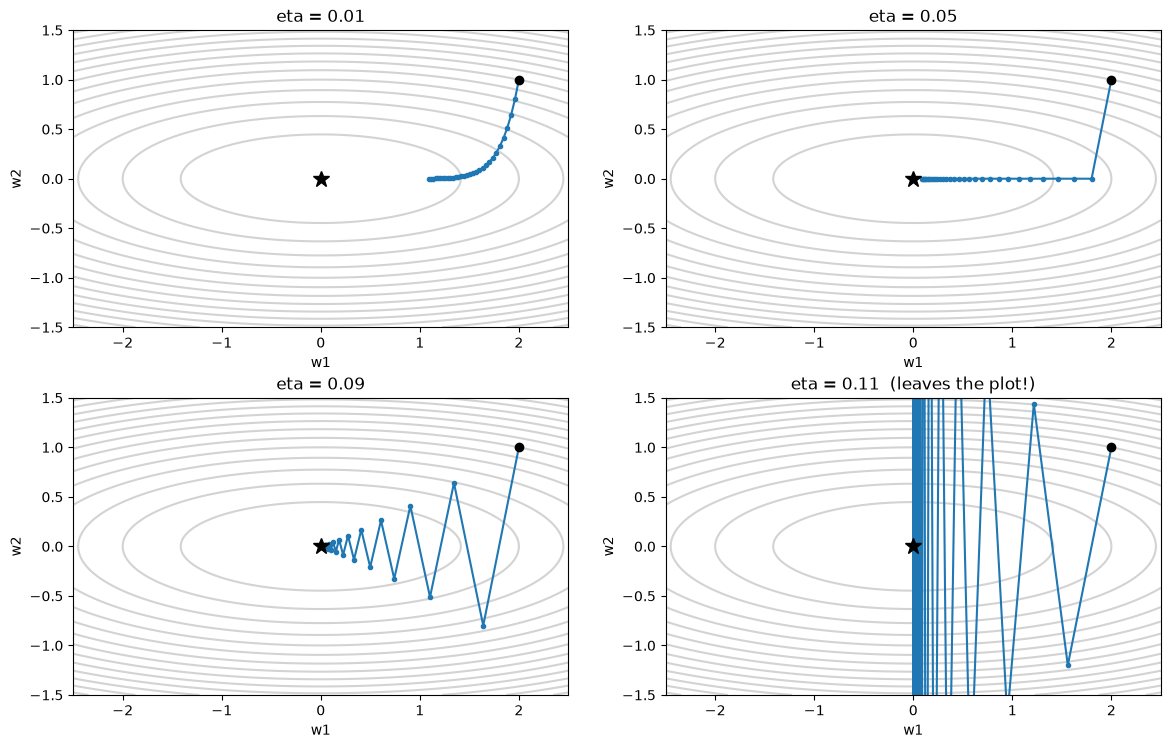

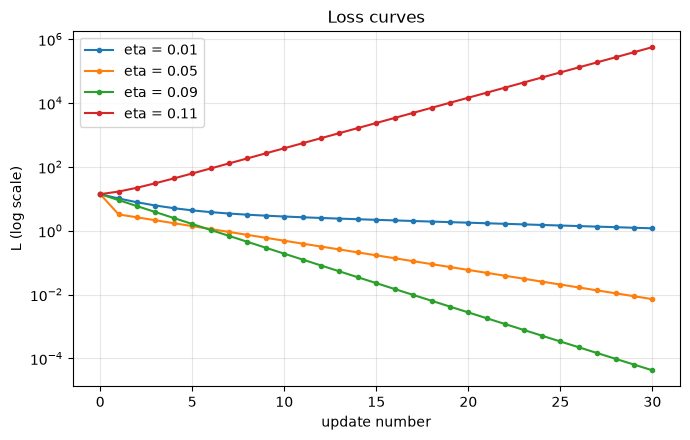

In [7]:
def gd2(lr, n_updates=30, start=(2., 1.)):
    path = [np.array(start)]
    for _ in range(n_updates):
        path.append(path[-1] - lr * grad2(path[-1]))
    path = np.array(path)
    losses = np.array([L2(p) for p in path])
    return path, losses


lrs2 = [0.01, 0.05, 0.09, 0.11]
res2 = {lr: gd2(lr) for lr in lrs2}
assert all(res2[lr][0].shape == (31, 2) for lr in lrs2)

print(f"{'eta':>5} {'w1 factor':>10} {'w2 factor':>10} {'w1 (30)':>14} {'w2 (30)':>14} {'L (30)':>14}")
for lr in lrs2:
    path, losses = res2[lr]
    print(f"{lr:5.2f} {1 - 2 * lr:10.2f} {1 - 20 * lr:10.2f} {path[-1, 0]:14.5g} {path[-1, 1]:14.5g} {losses[-1]:14.5g}")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, lr in zip(axes.ravel(), lrs2):
    path, losses = res2[lr]
    ax.contour(w1g, w2g, Z, levels=15, colors="lightgray")
    ax.plot(path[:, 0], path[:, 1], "o-", markersize=3)
    ax.plot(*path[0], "ko")
    ax.plot(0, 0, "k*", markersize=12)
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    note = "  (leaves the plot!)" if lr == 0.11 else ""
    ax.set_title(f"eta = {lr}{note}")
    ax.set_xlabel("w1"); ax.set_ylabel("w2")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4.5))
for lr in lrs2:
    plt.plot(range(31), res2[lr][1], "o-", markersize=3, label=f"eta = {lr}")
plt.yscale("log")
plt.xlabel("update number")
plt.ylabel("L (log scale)")
plt.title("Loss curves")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

**Why does the path not head straight to the minimum? Which learning rate is too slow, which zig-zags, and which blows up? In which direction does the zig-zag happen, and why that one?**

The gradient is perpendicular to the contours, and the contours are stretched ellipses, so -g doesn't point to the center. w2 is 10 times steeper than w1, so GD fixes w2 first and then crawls along w1.

Each update does $w_1 \to (1 - 2\eta)\,w_1$ and $w_2 \to (1 - 20\eta)\,w_2$:

- 0.01 is too slow: w1 factor is 0.98, after 30 updates w1 is still about 1.1.
- 0.05: w2 factor is 0, so w2 is gone after one update. No zig-zag.
- 0.09 zig-zags: w2 factor is -0.8, so w2 flips its sign every update but shrinks. It still converges.
- 0.11 blows up: w2 factor is -1.2, the zig-zag gets 20% bigger each update.

The zig-zag is in w2 because it's the steep direction. It only converges if |1 - 20η| < 1, so η < 0.1.

# Task 3

### Part A

In [8]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([1., 3., 5., 7., 9.])


def mse(w, b):
    yhat = w * x + b
    return np.mean((yhat - y) ** 2)


def gradients(w, b):
    yhat = w * x + b
    r = yhat - y
    dw = 2 * np.mean(r * x)
    db = 2 * np.mean(r)
    return dw, db


def gd(lr, n_updates):
    w, b = 0., 0.
    path = [(w, b)]
    history = [mse(w, b)]
    for _ in range(n_updates):
        dw, db = gradients(w, b)
        w, b = w - lr * dw, b - lr * db
        path.append((w, b))
        history.append(mse(w, b))
    return np.array(path), np.array(history)


print("loss at the start (w = 0, b = 0):", mse(0., 0.))

path, history = gd(0.05, 1)
print("lr = 0.05, after the first update: (w, b) =", path[1], " loss =", history[1])
assert np.isclose(mse(0., 0.), 33.0)
assert np.allclose(path[1], [1.4, 0.5]) and np.isclose(history[1], 3.61)

p, h = gd(0.05, 100)
print("path shape:", p.shape, " history shape:", h.shape)
assert p.shape == (101, 2) and h.shape == (101,)

loss at the start (w = 0, b = 0): 33.0
lr = 0.05, after the first update: (w, b) = [1.4 0.5]  loss = 3.6099999999999985
path shape: (101, 2)  history shape: (101,)


In [9]:
eps = 1e-6
w0_, b0_ = 1.3, -0.4
num_dw = (mse(w0_ + eps, b0_) - mse(w0_ - eps, b0_)) / (2 * eps)
num_db = (mse(w0_, b0_ + eps) - mse(w0_, b0_ - eps)) / (2 * eps)
print("numerical :", num_dw, num_db)
print("analytic  :", *gradients(w0_, b0_))
assert np.allclose([num_dw, num_db], gradients(w0_, b0_), atol=1e-5)

numerical : -13.999999999292356 -5.5999999997169425
analytic  : -14.0 -5.6


### Part B: the line learning

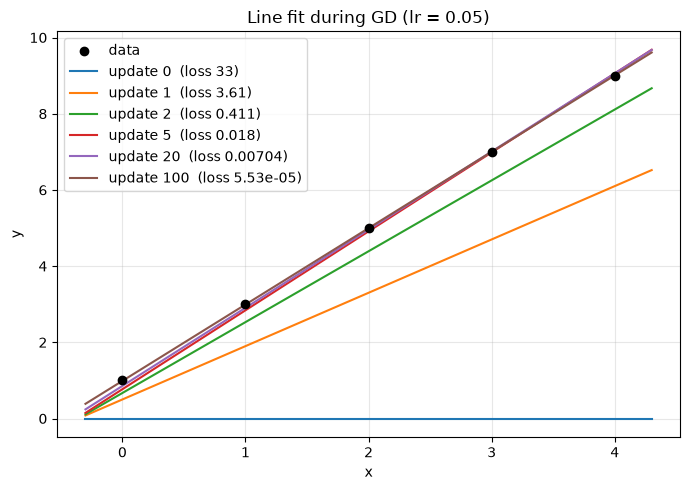

final (w, b) after 100 updates = [2.00450463 0.98715829]  (true values: 2, 1)


In [10]:
path, history = gd(0.05, 100)
x_line = np.linspace(-0.3, 4.3, 100)

plt.figure(figsize=(7, 5))
plt.scatter(x, y, color="black", zorder=5, label="data")
for k in [0, 1, 2, 5, 20, 100]:
    w_k, b_k = path[k]
    plt.plot(x_line, w_k * x_line + b_k, label=f"update {k}  (loss {history[k]:.3g})")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Line fit during GD (lr = 0.05)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("final (w, b) after 100 updates =", path[-1], " (true values: 2, 1)")

### Part C: the path on the loss surface

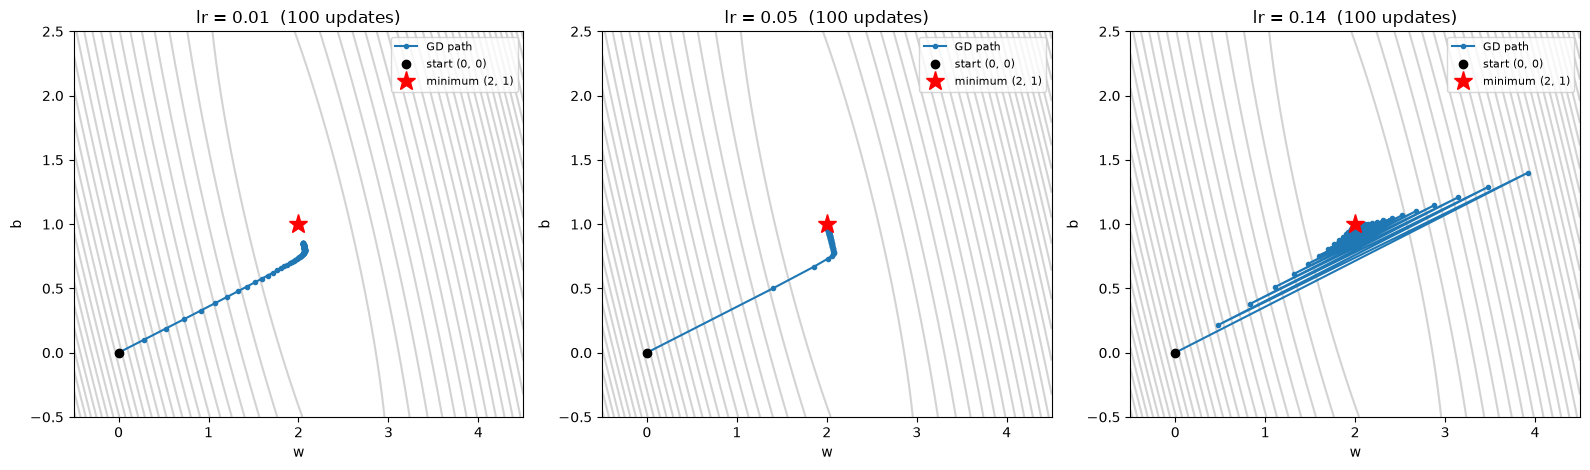

lr = 0.01  final loss after 100 updates = 0.007148
lr = 0.05  final loss after 100 updates = 5.527e-05
lr = 0.14  final loss after 100 updates = 7.388e-10
lr = 0.16  final loss after 100 updates = 1.743e+13


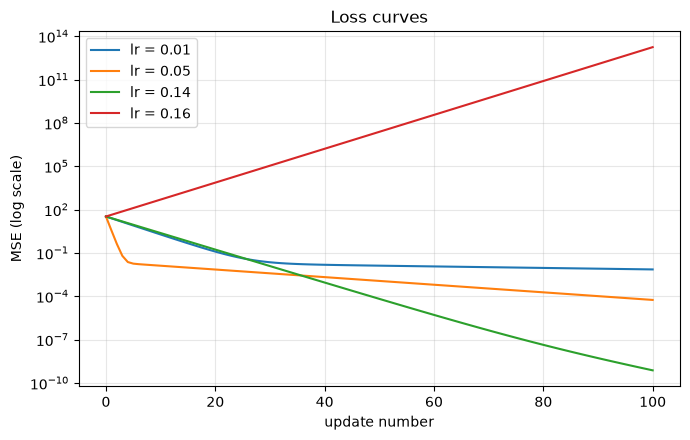

In [11]:
w_vals = np.linspace(-0.5, 4.5, 200)
b_vals = np.linspace(-0.5, 2.5, 200)
Wg, Bg = np.meshgrid(w_vals, b_vals)
Lg = np.mean((Wg[..., None] * x + Bg[..., None] - y) ** 2, axis=-1)
assert np.isclose(Lg[np.argmin(np.abs(b_vals - 1)), np.argmin(np.abs(w_vals - 2))], 0, atol=0.05)

lrs3 = [0.01, 0.05, 0.14]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, lr in zip(axes, lrs3):
    pth, _ = gd(lr, 100)
    ax.contour(Wg, Bg, Lg, levels=30, colors="lightgray")
    ax.plot(pth[:, 0], pth[:, 1], "o-", markersize=3, label="GD path")
    ax.plot(*pth[0], "ko", label="start (0, 0)")
    ax.plot(2, 1, "r*", markersize=14, label="minimum (2, 1)")
    ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 2.5)
    ax.set_xlabel("w"); ax.set_ylabel("b")
    ax.set_title(f"lr = {lr}  (100 updates)")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4.5))
for lr in [0.01, 0.05, 0.14, 0.16]:
    _, hist = gd(lr, 100)
    plt.plot(hist, label=f"lr = {lr}")
    print(f"lr = {lr:<5} final loss after 100 updates = {hist[-1]:.4g}")
plt.yscale("log")
plt.xlabel("update number")
plt.ylabel("MSE (log scale)")
plt.title("Loss curves")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
H = np.array([[2 * np.mean(x ** 2), 2 * np.mean(x)],
              [2 * np.mean(x),      2.0]])
eigvals, eigvecs = np.linalg.eigh(H)
print("Hessian =\n", H)
print("eigenvalues (curvatures):", eigvals)
print("shallow direction (w, b):", eigvecs[:, 0], "   steep direction (w, b):", eigvecs[:, 1])
print("largest stable lr = 2 / lambda_max =", 2 / eigvals[1])
for lr in [0.01, 0.05, 0.14, 0.16]:
    print(f"lr = {lr:<5} per-update factors: steep {1 - lr * eigvals[1]:7.3f}   shallow {1 - lr * eigvals[0]:6.3f}")

p5, _ = gd(0.05, 100)
k_w = np.argmax(np.abs(p5[:, 0] - 2) < 0.05)
k_b = np.argmax(np.abs(p5[:, 1] - 1) < 0.05)
print(f"\nlr = 0.05: w is within 0.05 of 2 after {k_w} updates, b is within 0.05 of 1 after {k_b} updates")

Hessian =
 [[12.  4.]
 [ 4.  2.]]
eigenvalues (curvatures): [ 0.59687576 13.40312424]
shallow direction (w, b): [ 0.33100694 -0.94362832]    steep direction (w, b): [-0.94362832 -0.33100694]
largest stable lr = 2 / lambda_max = 0.14921894064178784
lr = 0.01  per-update factors: steep   0.866   shallow  0.994
lr = 0.05  per-update factors: steep   0.330   shallow  0.970
lr = 0.14  per-update factors: steep  -0.876   shallow  0.916
lr = 0.16  per-update factors: steep  -1.144   shallow  0.904

lr = 0.05: w is within 0.05 of 2 after 3 updates, b is within 0.05 of 1 after 56 updates


1. In B, which parameter gets close to its correct value first, $w$ or $b$? Use the shape of the contours in C to explain why.
2. Describe the path for lr = 0.14. It looks wild at first - does it end up better or worse than lr = 0.05 after 100 updates? What happens with lr = 0.16?
3. If you had a new problem and no idea which learning rate to use, how would you choose one using what you saw here?

1) w. With lr = 0.05 it's within 0.05 of 2 after 3 updates, b needs 56 updates to get close to 1. The contours are thin tilted ellipses: the steep direction is mostly w and the long flat valley is mostly b. So GD fixes w fast, then b slowly crawls along the valley.

2) With lr = 0.14 the first update jumps to (3.92, 1.4), way past the target, and then it bounces between the walls of the valley, a bit smaller each time. It still ends better than lr = 0.05 (loss about 7e-10 vs 5.5e-5), because it moves faster along the flat valley. With lr = 0.16 the bounces get bigger every update, so it diverges (loss about 1e13). The limit is around 0.149.

3) I'd try learning rates on a log scale (0.001, 0.01, 0.1, ...) for a short run and look at the loss curves. If the loss explodes, go lower. If it goes down too slowly, go higher. Pick the biggest one that still goes down nicely, and stay a bit below the edge to be safe.

### Optional: Homework 3 network trained with GD

after   0 updates: MSE = 0.984375
after  10 updates: MSE = 0.096418
after  50 updates: MSE = 0.026032
after 300 updates: MSE = 0.000002


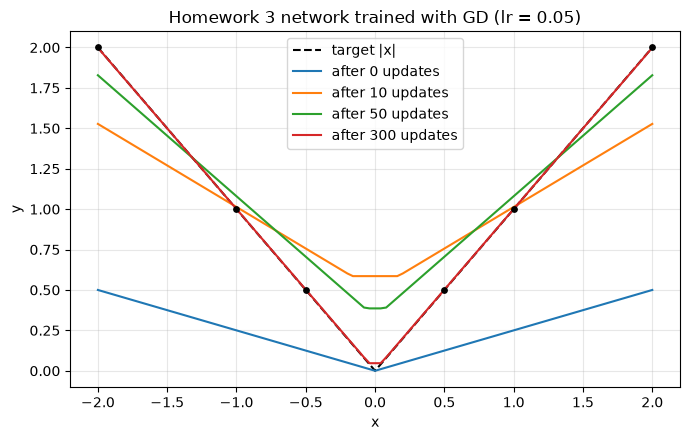

In [13]:
X_net = np.array([[-2.], [-1.], [-0.5], [0.5], [1.], [2.]])
y_net = np.abs(X_net)

params = {
    "W1": np.array([[0.5, -0.5]]),
    "b1": np.array([0., 0.]),
    "W2": np.array([[0.5], [0.5]]),
    "b2": np.array([0.]),
}


def net_forward(params, X):
    Z1 = X @ params["W1"] + params["b1"]
    H = np.maximum(0.0, Z1)
    return Z1, H, H @ params["W2"] + params["b2"]


def net_mse(params, X, y):
    return np.mean((net_forward(params, X)[2] - y) ** 2)


def net_gradients(params, X, y):
    Z1, H, Yhat = net_forward(params, X)
    G = (2.0 / X.shape[0]) * (Yhat - y)
    D = (G @ params["W2"].T) * (Z1 > 0)
    return {"W1": X.T @ D, "b1": D.sum(axis=0), "W2": H.T @ G, "b2": G.sum(axis=0)}


snapshots = {}
p_net = {k: v.copy() for k, v in params.items()}
for step in range(301):
    if step in (0, 10, 50, 300):
        snapshots[step] = {k: v.copy() for k, v in p_net.items()}
        print(f"after {step:3d} updates: MSE = {net_mse(p_net, X_net, y_net):.6f}")
    grads = net_gradients(p_net, X_net, y_net)
    p_net = {k: p_net[k] - 0.05 * grads[k] for k in p_net}

xs = np.linspace(-2, 2, 101).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.plot(xs, np.abs(xs), "k--", label="target |x|")
for step, prm in snapshots.items():
    plt.plot(xs, net_forward(prm, xs)[2], label=f"after {step} updates")
plt.scatter(X_net, y_net, color="black", zorder=5, s=15)
plt.xlabel("x"); plt.ylabel("y")
plt.title("Homework 3 network trained with GD (lr = 0.05)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

After 300 updates the curve is very close to |x| (MSE about 2e-6), with W1 close to (1, -1) and W2 close to (1, 1), which is basically ReLU(x) + ReLU(-x).